# NBO Assist GenAI — Amazon Reviews 2023 | Versión 8
**Actividad 4 · Tecmilenio · Prototipo académico**

**ROGELIO ACO GONZALEZ**

**Profesor: LUIS ARIEL VAZQUEZ PIÑA**

Intento 8

Objetivo: Identificar e implementar el modelo preentrenado más adecuado para 1. Identificar la Next Best Offer (NBO) y un argumento de venta generado por un IA Generativa.

Se mantiene el objetivo principal de los trabajos anteriores, pero se cambia el entorno de banco hacia negocio retial porque es en este último en donde se cuenta con datos para un ejercicio más real.

## 1. Entorno, dependencias y autenticación
**Se instalan las liberías y versiones necesarias para la ejecución**

In [1]:
%pip install -q "sentence-transformers>=3,<6" "transformers>=4.45,<5" "huggingface_hub>=0.25,<1" "accelerate>=0.33" "scikit-learn>=1.4" pandas numpy pyarrow matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [2]:
import os, sys, json, random, platform, time, gc
from pathlib import Path
import numpy as np, pandas as pd, torch
from huggingface_hub import hf_hub_download, login
SEED=42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
for folder in ('data','results','results/figures'): Path(folder).mkdir(parents=True,exist_ok=True)
DEVICE='cuda' if torch.cuda.is_available() else 'cpu'
print('Python:',platform.python_version(),'Torch:',torch.__version__,'Dispositivo:',DEVICE)
if DEVICE=='cuda': print('GPU:',torch.cuda.get_device_name(0))
try:
    from google.colab import userdata
    token=userdata.get('HF_TOKEN')
    if token: login(token=token,add_to_git_credential=False); print('Autenticación HF correcta')
    else: print('Sin HF_TOKEN: los modelos y datos públicos pueden descargarse sin autenticación.')
except Exception as e:
    print('Autenticación opcional no disponible:',type(e).__name__)

Python: 3.13.16 Torch: 2.11.0+cu130 Dispositivo: cuda
GPU: Tesla T4
Autenticación HF correcta


## 2. Datos oficiales y catálogo

Se buscaron datos en Hugging Face y se encontró información de venta de productos de Amazon.

Se descargan las tres particiones de benchmark y los metadatos publicados por McAuley Lab. La partición de prueba se reserva para la evaluación final. Los datos se descargan mediante rutas comprobadas en el repositorio, sin scripts heredados de `datasets`.

In [3]:
REPO='McAuley-Lab/Amazon-Reviews-2023'
PARTS={}
for split in ('train','valid','test'):
    filename=f'benchmark/0core/last_out_w_his/All_Beauty.{split}.csv'
    path=hf_hub_download(repo_id=REPO,repo_type='dataset',filename=filename)
    PARTS[split]=pd.read_csv(path,dtype={'user_id':'string','parent_asin':'string','history':'string'})
    print(split,len(PARTS[split]),PARTS[split].columns.tolist())
meta_path=hf_hub_download(repo_id=REPO,repo_type='dataset',filename='raw_meta_All_Beauty/full-00000-of-00001.parquet')
meta=pd.read_parquet(meta_path)
print('Metadatos:',len(meta),meta.columns.tolist())
assert {'user_id','parent_asin','rating','timestamp','history'}.issubset(PARTS['test'].columns)
assert {'parent_asin','title'}.issubset(meta.columns)

benchmark/0core/last_out_w_his/All_Beaut(…):   0%|          | 0.00/2.43M [00:00<?, ?B/s]

train 19120 ['user_id', 'parent_asin', 'rating', 'timestamp', 'history']


benchmark/0core/last_out_w_his/All_Beaut(…):   0%|          | 0.00/2.73M [00:00<?, ?B/s]

valid 42823 ['user_id', 'parent_asin', 'rating', 'timestamp', 'history']


benchmark/0core/last_out_w_his/All_Beaut(…):   0%|          | 0.00/37.9M [00:00<?, ?B/s]

test 631986 ['user_id', 'parent_asin', 'rating', 'timestamp', 'history']


raw_meta_All_Beauty/full-00000-of-00001.(…):   0%|          | 0.00/59.6M [00:00<?, ?B/s]

Metadatos: 112590 ['main_category', 'title', 'average_rating', 'rating_number', 'features', 'description', 'price', 'images', 'videos', 'store', 'categories', 'details', 'parent_asin', 'bought_together', 'subtitle', 'author']


## 3. Preparación reproducible de pares
**Lo mas relevante de este paso que haremos la asociación de un cliente con un producto para que mas adelante se identifique su relación, gusto o propensión**

La etiqueta `label_proxy=1` corresponde al producto observado como objetivo en el benchmark. `label_proxy=0` corresponde a candidatos no observados; esto es una simplificación de evaluación, no evidencia de rechazo. Se descartan perfiles sin historial y productos sin descripción. El muestreo y los candidatos se fijan por semilla. No se utiliza el producto objetivo para construir el perfil.

In [4]:
def text_item(row):
    title=str(row.get('title') or '').strip()
    features=row.get('features')
    if not isinstance(features,(list,tuple,np.ndarray)): features=[]
    return (title+' '+ ' '.join(map(str,list(features)[:2])))[:350].strip()

catalog=meta.dropna(subset=['parent_asin','title']).drop_duplicates('parent_asin').copy()
catalog['product_text']=catalog.apply(text_item,axis=1)
catalog=catalog[catalog['product_text'].str.len()>8].set_index('parent_asin')
ITEMS=sorted(catalog.index.astype(str).tolist())
print('Productos con texto:',len(ITEMS))

def prepare_split(split, max_users=80, negatives=4, seed=42):
    rng=random.Random(seed)
    src=PARTS[split].copy()
    src=src[src['rating'].ge(4) & src['parent_asin'].isin(catalog.index)].copy()
    src=src.sort_values(['user_id','timestamp','parent_asin'])
    src=src.drop_duplicates('user_id',keep='last')
    eligible=[]
    for r in src.itertuples(index=False):
        hist=[] if pd.isna(r.history) else str(r.history).split()
        hist=[x for x in hist if x in catalog.index and x != r.parent_asin]
        if not hist: continue
        eligible.append((str(r.user_id),str(r.parent_asin),hist,int(r.timestamp)))
    eligible.sort(key=lambda x:(x[0],x[3],x[1]))
    rng.shuffle(eligible)
    rows=[]
    for uid,target,hist,ts in eligible:
        if len(rows)//(negatives+1)>=max_users:break
        profile=' | '.join(str(catalog.loc[p,'product_text']) for p in hist[-4:])[:1000]
        if not profile.strip():continue
        excluded=set(hist+[target]); neg=[]
        for _ in range(negatives):
            for attempt in range(300):
                p=rng.choice(ITEMS)
                if p not in excluded:
                    neg.append(p);excluded.add(p);break
        if len(neg)!=negatives:continue
        group_id=f'{split}_{len(rows)//(negatives+1):04d}'
        for item,label in [(target,1)]+[(p,0) for p in neg]:
            rows.append(dict(group_id=group_id,user_id=uid,candidate_asin=item,profile_text=profile,
                product_text=str(catalog.loc[item,'product_text']),product_title=str(catalog.loc[item,'title'])[:180],
                label_proxy=label,split=split,reference_timestamp=ts))
    out=pd.DataFrame(rows)
    if out.empty:raise RuntimeError(f'Sin usuarios elegibles en {split}; inspecciona history y el catálogo.')
    assert out.groupby('group_id').label_proxy.sum().eq(1).all()
    assert out.groupby('group_id').size().eq(negatives+1).all()
    return out

# Validación y prueba son independientes. El conjunto train se conserva como evidencia de origen.
valid_df=prepare_split('valid',max_users=80,seed=SEED)
test_df=prepare_split('test',max_users=80,seed=SEED+1)
valid_df.to_csv('data/valid_evaluacion.csv',index=False)
test_df.to_csv('data/dataset_evaluacion.csv',index=False)
print('Validación:',len(valid_df),'pares /',valid_df.group_id.nunique(),'grupos')
print('Prueba:',len(test_df),'pares /',test_df.group_id.nunique(),'grupos')
display(test_df[['group_id','product_title','label_proxy']].head(10))

Productos con texto: 112467
Validación: 400 pares / 80 grupos
Prueba: 400 pares / 80 grupos


,group_id,product_title,label_proxy
0,test_0000,JUSU Body Smoky Cedar Deodorant - 100% Natural...,1
1,test_0000,Masque Mango Sexual Flavors Singles Wallet - T...,0
2,test_0000,Aveda Hydrating Lotion 1.7oz,0
3,test_0000,BONNET QUEEN Double Layer Silk Bonnet Satin Bo...,0
4,test_0000,Manicure Kit Pedicure Kit Nose Hair Scissors E...,0
5,test_0001,"Makeup brushes,ABCsell 2017 12Pcs Blending Pen...",1
6,test_0001,Fake Bake Flawless with Fake Bake Body Mate Ap...,0
7,test_0001,"Quick Beard Straightener Comb, 2019 Profession...",0
8,test_0001,"Floral Tumbler, Daisy Gifts for Women, Plant L...",0
9,test_0001,Wet N Wild Perfect Pout Gel Lip Balm - #954B T...,0


### Auditoría de separación temporal y usuarios
Las particiones oficiales pueden compartir usuarios: se mide el solapamiento y se verifica que el historial de cada ejemplo sea anterior al producto objetivo. **No se presupone independencia por usuario.**

In [5]:
from collections import Counter
from datetime import datetime, timezone
split_users={s:set(PARTS[s].user_id.dropna().astype(str)) for s in ('train','valid','test')}
audit=[]
for a,b in [('train','valid'),('train','test'),('valid','test')]:
    audit.append({'particiones':f'{a}/{b}','usuarios_compartidos':len(split_users[a]&split_users[b])})
display(pd.DataFrame(audit))
# Comprobación de que el objetivo no esté explícitamente dentro de history.
for s in ('valid','test'):
    part=PARTS[s]
    repeated=sum(str(r.parent_asin) in (str(r.history).split() if pd.notna(r.history) else []) for r in part.itertuples(index=False))
    print(s,'objetivos repetidos en history:',repeated)
# Verificación temporal basada en el orden del historial proporcionado por el benchmark.
# No hay timestamps individuales de cada elemento de history; por ello no se puede auditar
# independientemente su cronología solo con este CSV.
pd.DataFrame(audit).to_csv('results/auditoria_particiones.csv',index=False)


,particiones,usuarios_compartidos
0,train/valid,8151
1,train/test,8151
2,valid/test,42823


valid objetivos repetidos en history: 0
test objetivos repetidos en history: 0


## 4. Tres modelos preentrenados y métricas
**Debemos considerar los eleentos que tenemos y los que no tenemos, contamos con información de preferencias del cliente, y compras anteriores, pero no contamos con datos como su ingreso, sus necesidades actuales, su ciclo de vida o probabilidad de intención de compra**

=== LOS MODELOS QUE SE USARÁN PARA EVALUAR SE ESCOGIERON PENSANDO EN LOS ELEMENTOS QUE TENEMOS Y EN LOS ELEMENTOS QUE NO TENEMOS ===

En un entporno bancario real, la selección del modelo puede ser muy distinta y dependerá de la cantidad de datos que se pueden obteber del cliente, hay que considerar que se puede tener información formal del cliente como ingresos, estado civil, edad, etc y comunmente son datos reales. Por otro lado ,se carece de datos referentes a gustos, preferencias, relaciones familiares, aspiraciones, mientras que mucho de esto comunmente se comparte mas en redes sociales.

Se usan embeddings normalizados y similitud coseno. Para métricas binarias se fija el umbral 0.5 **antes** de mirar test. HitRate@1 compara cuál de cinco candidatos recibe mayor puntuación. La latencia incluye codificación por lotes de perfiles y candidatos, excluye la carga inicial y el calentamiento. Los resultados deben ejecutarse en Colab; no hay métricas prefabricadas.

In [6]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics import accuracy_score,precision_recall_fscore_support
MODELS={
 'MiniLM-L6':'sentence-transformers/all-MiniLM-L6-v2',
 'MPNet-base':'sentence-transformers/all-mpnet-base-v2',
 'MultiQA-MiniLM':'sentence-transformers/multi-qa-MiniLM-L6-cos-v1'
}

def score_models(frame, split_name, threshold=0.5):
    summaries=[]; predictions=[]
    for name,model_id in MODELS.items():
        if DEVICE=='cuda':torch.cuda.empty_cache();torch.cuda.reset_peak_memory_stats()
        t0=time.perf_counter();model=SentenceTransformer(model_id,device=DEVICE,trust_remote_code=False)
        load_s=time.perf_counter()-t0
        model.encode(['warmup'],normalize_embeddings=True,show_progress_bar=False)
        if DEVICE=='cuda':torch.cuda.synchronize()
        t0=time.perf_counter()
        profiles=model.encode(frame.profile_text.tolist(),batch_size=32,normalize_embeddings=True,show_progress_bar=False)
        products=model.encode(frame.product_text.tolist(),batch_size=32,normalize_embeddings=True,show_progress_bar=False)
        if DEVICE=='cuda':torch.cuda.synchronize()
        infer_s=time.perf_counter()-t0
        scores=np.sum(profiles*products,axis=1)
        predicted=(scores>=threshold).astype(int)
        y=frame.label_proxy.to_numpy(dtype=int)
        precision,recall,f1,_=precision_recall_fscore_support(y,predicted,average='binary',zero_division=0)
        p=frame[['group_id','user_id','candidate_asin','product_title','label_proxy','split']].copy()
        p['modelo']=name;p['score']=scores;p['pred_binaria']=predicted
        winners=p.sort_values(['group_id','score','candidate_asin'],ascending=[True,False,True]).drop_duplicates('group_id')
        summaries.append(dict(split=split_name,modelo=name,model_id=model_id,accuracy_proxy=accuracy_score(y,predicted),precision_proxy=precision,recall_proxy=recall,f1_proxy=f1,hit_rate_at_1_proxy=winners.label_proxy.mean(),latencia_ms_por_par=1000*infer_s/len(frame),tiempo_carga_s=load_s,memoria_gpu_gb=torch.cuda.max_memory_allocated()/1e9 if DEVICE=='cuda' else None,umbral=threshold,pares=len(frame),grupos=frame.group_id.nunique()))
        predictions.append(p)
        del model,profiles,products;gc.collect()
        if DEVICE=='cuda':torch.cuda.empty_cache()
    return pd.DataFrame(summaries),pd.concat(predictions,ignore_index=True)

In [7]:
# Primero validación; después prueba independiente. No se ajustan hiperparámetros con test.
valid_metrics,valid_predictions=score_models(valid_df,'valid')
print('VALIDACIÓN');display(valid_metrics)
test_metrics,test_predictions=score_models(test_df,'test')
print('PRUEBA');display(test_metrics)
valid_metrics.to_csv('results/metricas_valid.csv',index=False)
test_metrics.to_csv('results/metricas_modelos.csv',index=False)
test_predictions.to_csv('results/predicciones_modelos.csv',index=False)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/90.9M [00:00<?, ?B/s]

... (27 outputs left out)

VALIDACIÓN


,split,modelo,model_id,accuracy_proxy,precision_proxy,recall_proxy,f1_proxy,hit_rate_at_1_proxy,latencia_ms_por_par,tiempo_carga_s,memoria_gpu_gb,umbral,pares,grupos
0,valid,MiniLM-L6,sentence-transformers/all-MiniLM-L6-v2,0.825,0.656250,0.2625,0.375000,0.4750,1.819382,5.360802,0.210286,0.5,400,80
1,valid,MPNet-base,sentence-transformers/all-mpnet-base-v2,0.815,0.578947,0.2750,0.372881,0.4375,7.030586,8.372842,0.757894,0.5,400,80
2,valid,MultiQA-MiniLM,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,0.835,0.769231,0.2500,0.377358,0.5250,1.630290,4.165726,0.210941,0.5,400,80


PRUEBA


,split,modelo,model_id,accuracy_proxy,precision_proxy,recall_proxy,f1_proxy,hit_rate_at_1_proxy,latencia_ms_por_par,tiempo_carga_s,memoria_gpu_gb,umbral,pares,grupos
0,test,MiniLM-L6,sentence-transformers/all-MiniLM-L6-v2,0.825,0.678571,0.2375,0.351852,0.4625,1.452744,2.031931,0.206506,0.5,400,80
1,test,MPNet-base,sentence-transformers/all-mpnet-base-v2,0.810,0.541667,0.3250,0.406250,0.4000,5.907038,2.048751,0.739180,0.5,400,80
2,test,MultiQA-MiniLM,sentence-transformers/multi-qa-MiniLM-L6-cos-v1,0.825,0.727273,0.2000,0.313725,0.4125,1.420018,1.911289,0.206506,0.5,400,80


## 5. Referencias y análisis de errores
La referencia aleatoria tiene una expectativa de HitRate@1 de 1/5 = 20% bajo cinco candidatos. La referencia de popularidad utiliza **solo** la partición de entrenamiento, evitando usar la prueba para estimar popularidad. No se debe inferir que una diferencia pequeña sea estadísticamente concluyente con 80 grupos.

**Es importante destacar que cada métrica tiene un objetivo de precición, calidad, velocidad, etc. Para seleccionar el modelo más adecuado se debe tener muy claro las necesidades del negocio, sus capacidades y restricciones. Por ejemplo en un banco, el volumen de transacciones simultáneas y la velocidad con la que se responde es super importante**

In [8]:
# Baseline de popularidad construido exclusivamente con TRAIN
popular=PARTS['train'].groupby('parent_asin').size().to_dict()
base=test_df[['group_id','candidate_asin','label_proxy']].copy()
base['score_popularidad']=base.candidate_asin.map(popular).fillna(0)
winners=base.sort_values(['group_id','score_popularidad','candidate_asin'],ascending=[True,False,True]).drop_duplicates('group_id')
print('HitRate@1 esperado aleatorio:',round(1/5,3))
print('HitRate@1 popularidad:',round(winners.label_proxy.mean(),3))
print('HitRate@1 modelos:');display(test_metrics[['modelo','hit_rate_at_1_proxy','f1_proxy','latencia_ms_por_par']])
errors=[]
for name,g in test_predictions.groupby('modelo'):
    winners=g.sort_values(['group_id','score','candidate_asin'],ascending=[True,False,True]).drop_duplicates('group_id')
    errors.append(dict(modelo=name,aciertos=int(winners.label_proxy.sum()),errores=int((1-winners.label_proxy).sum())))
pd.DataFrame(errors).to_csv('results/errores_por_modelo.csv',index=False)

HitRate@1 esperado aleatorio: 0.2
HitRate@1 popularidad: 0.462
HitRate@1 modelos:


,modelo,hit_rate_at_1_proxy,f1_proxy,latencia_ms_por_par
0,MiniLM-L6,0.4625,0.351852,1.452744
1,MPNet-base,0.4000,0.406250,5.907038
2,MultiQA-MiniLM,0.4125,0.313725,1.420018


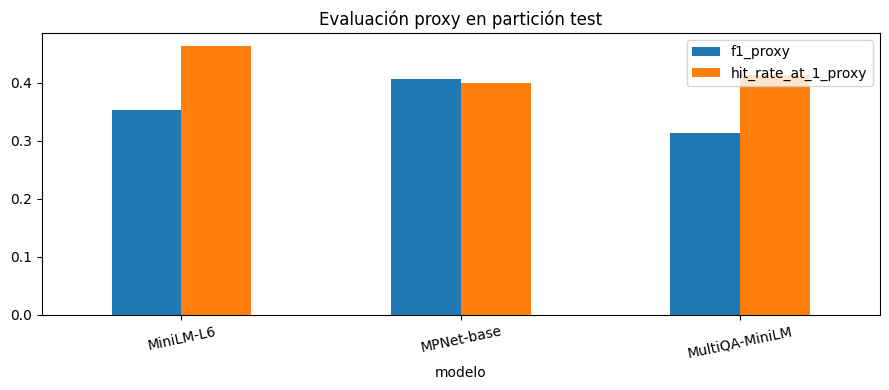

In [9]:
import matplotlib.pyplot as plt
ax=test_metrics.plot.bar(x='modelo',y=['f1_proxy','hit_rate_at_1_proxy'],figsize=(9,4),rot=12,title='Evaluación proxy en partición test')
plt.tight_layout();plt.savefig('results/figures/comparacion_modelos.png',dpi=150,bbox_inches='tight');plt.show()

## 6. NBO calculado → argumento de venta
Se elige el modelo con mayor HitRate@1 en validación (desempate por menor latencia). Para evitar usar `test` para elegir el modelo, la elección se hace **antes** de consultar los resultados de prueba. El producto NBO se selecciona por su puntuación máxima dentro de un grupo de test; no se utiliza `df.iloc[0]`. Qwen solo redacta, no modifica el ranking. El argumento es un borrador sujeto a revisión humana.

El texto generado es un borrador no aprobado. Se usarán únicamente título e identificador de producto; no se incorporarán características inconsistentes.

In [10]:
# Selección basada exclusivamente en validación
chosen=valid_metrics.sort_values(['hit_rate_at_1_proxy','latencia_ms_por_par'],ascending=[False,True]).iloc[0]
chosen_name=chosen['modelo']
print('Modelo elegido por validación:',chosen_name)
# Selección de un grupo demostrativo: primero en orden fijo, sin buscar aciertos
selected_group=sorted(test_df.group_id.unique())[0]
candidates=test_predictions[(test_predictions.modelo==chosen_name)&(test_predictions.group_id==selected_group)]
selected=candidates.sort_values(['score','candidate_asin'],ascending=[False,True]).iloc[0]
product=test_df[(test_df.group_id==selected_group)&(test_df.candidate_asin==selected.candidate_asin)].iloc[0]
print('Grupo:',selected_group,'Producto NBO:',product.product_title,'Score:',round(float(selected.score),4))
print('Etiqueta proxy (solo auditoría):',int(product.label_proxy))

Modelo elegido por validación: MultiQA-MiniLM
Grupo: test_0000 Producto NBO: JUSU Body Smoky Cedar Deodorant - 100% Natural - 3 oz Score: 0.4043
Etiqueta proxy (solo auditoría): 1


In [11]:
import re
from transformers import pipeline

# El título solo acredita la identificación comercial, no beneficios ni eficacia.
def catalog_evidence(asin):
    row=catalog.loc[str(asin)]
    title=str(row.get('title','')).strip()
    if not title or title.lower() in ('nan','none'):
        raise ValueError('Falta título de producto')
    return {'asin':str(asin),'title':title,'verified_benefits':[]}

def prompt_argumento(evidence):
    return f"""Eres asistente comercial para un prototipo académico. Contesta SOLO en español.
Producto: {evidence['title']}
ASIN: {evidence['asin']}
No hay beneficios, precio, inventario, garantías ni eficacia verificados.
Redacta exactamente cuatro líneas con estos encabezados:
APERTURA: Invitación neutral a conocer el producto, sin prometer beneficios.
BENEFICIOS VERIFICABLES: No hay atributos verificados suficientes para afirmar beneficios.
PREGUNTAS ABIERTAS: Dos preguntas abiertas sobre necesidades y preferencias.
ADVERTENCIAS: Información comercial por verificar y revisión humana obligatoria.
No inventes propiedades, composición, beneficios, precio, promociones ni preferencias del cliente.
"""

REQUIRED=['APERTURA','BENEFICIOS VERIFICABLES','PREGUNTAS ABIERTAS','ADVERTENCIAS']
UNSUPPORTED=re.compile(r'\b(garantizad[oa]s?|cura|curativo|descuento|gratis|100\s*%\s*eficaz|hidrata|hidratante|suaviza|antibacterial|hipoalerg[eé]nico)\b',re.I)

def validate_argument(text, evidence):
    text=str(text).strip()
    flags=[]
    lines=[line.strip() for line in text.splitlines() if line.strip()]
    headings=[]
    for line in lines:
        match=re.match(r'^([A-ZÁÉÍÓÚ ]+):\s*(.*)$',line)
        if match: headings.append(match.group(1).strip())
    if headings != REQUIRED:
        flags.append('Estructura incompleta o fuera de orden')
    if len(lines)!=4:
        flags.append('Se requieren exactamente cuatro líneas')
    if 'No hay atributos verificados suficientes para afirmar beneficios' not in text:
        flags.append('No declara insuficiencia de evidencia')
    if UNSUPPORTED.search(text):
        flags.append('Contiene términos de beneficios o promesas sin respaldo')
    if not evidence.get('title') or not evidence.get('asin'):
        flags.append('Identidad del producto incompleta')
    if not re.search(r'revisi[oó]n humana',text,re.I):
        flags.append('No exige revisión humana')
    # Este control estructural no valida semánticamente todas las afirmaciones.
    return {'estructura_valida':not flags,'alertas':flags,'aprobacion_humana':'PENDIENTE',
            'apto_para_uso_comercial':False}

def safe_fallback(evidence):
    return '\n'.join([
        'APERTURA: ¿Te gustaría conocer este producto y revisar si responde a lo que buscas?',
        'BENEFICIOS VERIFICABLES: No hay atributos verificados suficientes para afirmar beneficios.',
        'PREGUNTAS ABIERTAS: ¿Qué características valoras más? ¿Qué información necesitarías para evaluarlo?',
        'ADVERTENCIAS: Información comercial por verificar y revisión humana obligatoria.'
    ])

evidence=catalog_evidence(selected.candidate_asin)
print('NBO calculado:',evidence['title'],'ASIN:',evidence['asin'],'Modelo:',chosen_name)

generator=pipeline('text-generation',model='Qwen/Qwen2.5-0.5B-Instruct',device_map='auto',dtype='auto')
response=generator([{'role':'user','content':prompt_argumento(evidence)}],
                   max_new_tokens=360,do_sample=False,return_full_text=False)
raw=response[0]['generated_text']
if isinstance(raw,list):
    raw='\n'.join(str(x.get('content','')) for x in raw if isinstance(x,dict))
raw=str(raw).strip()
initial_review=validate_argument(raw,evidence)

# Fail closed: nunca presentar como aprobado un texto que incumple las reglas.
if initial_review['alertas']:
    final_argument=safe_fallback(evidence)
    generation_status='BLOQUEADO: salida generativa sustituida por plantilla neutral'
else:
    final_argument=raw
    generation_status='PENDIENTE: validación humana antes de uso comercial'
final_review=validate_argument(final_argument,evidence)
assert not final_review['alertas'], final_review['alertas']

review={'asin':evidence['asin'],'producto':evidence['title'],'modelo_nbo':chosen_name,
        'score_afinidad':float(selected.score),'estado_generacion':generation_status,
        'alertas_generacion':initial_review['alertas'],'revision_plantilla':final_review,
        'aprobacion_humana':'PENDIENTE','apto_para_uso_comercial':False,
        'limitaciones':'Las reglas automáticas no certifican veracidad, elegibilidad ni cumplimiento.'}
Path('results/argumento_generado_sin_aprobar.txt').write_text(raw,encoding='utf-8')
Path('results/argumento_demo.txt').write_text(final_argument,encoding='utf-8')
Path('results/revision_argumento.json').write_text(json.dumps(review,ensure_ascii=False,indent=2),encoding='utf-8')
Path('results/nbo_seleccionado.json').write_text(json.dumps({'asin':evidence['asin'],'titulo':evidence['title'],
 'modelo':chosen_name,'score_afinidad':float(selected.score)},ensure_ascii=False,indent=2),encoding='utf-8')
print('Estado:',generation_status)
print(final_argument)
print('Aprobación humana:',review['aprobacion_humana'])


NBO calculado: JUSU Body Smoky Cedar Deodorant - 100% Natural - 3 oz ASIN: B0794KTDSL Modelo: MultiQA-MiniLM


config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Device set to use cuda:0
The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Estado: BLOQUEADO: salida generativa sustituida por plantilla neutral
APERTURA: ¿Te gustaría conocer este producto y revisar si responde a lo que buscas?
BENEFICIOS VERIFICABLES: No hay atributos verificados suficientes para afirmar beneficios.
PREGUNTAS ABIERTAS: ¿Qué características valoras más? ¿Qué información necesitarías para evaluarlo?
ADVERTENCIAS: Información comercial por verificar y revisión humana obligatoria.
Aprobación humana: PENDIENTE


In [12]:
# Pruebas negativas: un texto con beneficios inventados debe bloquearse.
malicious="""APERTURA: Compra ahora este producto garantizado.
BENEFICIOS VERIFICABLES: Hidrata y cura la piel.
PREGUNTAS ABIERTAS: ¿Lo compras? ¿Quieres otro?
ADVERTENCIAS: Revisión humana obligatoria."""
negative_review=validate_argument(malicious,evidence)
assert negative_review['alertas'], 'Fallo: no se detectó el texto inseguro'
missing_review=validate_argument('APERTURA: Hola',{'asin':'','title':''})
assert missing_review['alertas'], 'Fallo: no se detectó información insuficiente'
assert review['apto_para_uso_comercial'] is False
print('Pruebas negativas superadas:',negative_review['alertas'],missing_review['alertas'])
Path('results/pruebas_seguridad.json').write_text(json.dumps({
 'texto_con_promesas_bloqueado':bool(negative_review['alertas']),
 'identidad_incompleta_bloqueada':bool(missing_review['alertas']),
 'aprobacion_humana':'PENDIENTE'},ensure_ascii=False,indent=2),encoding='utf-8')


Pruebas negativas superadas: ['No declara insuficiencia de evidencia', 'Contiene términos de beneficios o promesas sin respaldo'] ['Estructura incompleta o fuera de orden', 'Se requieren exactamente cuatro líneas', 'No declara insuficiencia de evidencia', 'Identidad del producto incompleta', 'No exige revisión humana']


120

## 7. Registro del entorno, evidencias y descarga
El ZIP contiene resultados ejecutados; nunca incluye el token de Hugging Face. El notebook debe guardarse desde Colab con las salidas de ejecución. Antes de subir a GitHub, revisar que el repositorio no incluya datos personales identificables; los identificadores de usuario de Amazon se anonimizan en las exportaciones públicas.

In [13]:
import importlib.metadata as im
versions={x:im.version(x) for x in ['sentence-transformers','transformers','huggingface-hub','scikit-learn','pandas','numpy','torch']}
config={'python':platform.python_version(),'device':DEVICE,'seed':SEED,'versions':versions,'dataset':REPO,'benchmark':'0core/last_out_w_his','category':'All_Beauty','valid_groups':int(valid_df.group_id.nunique()),'test_groups':int(test_df.group_id.nunique()),'candidates_per_group':5,'threshold':0.5,'limitations':['No observados no son rechazos','Valoración positiva no equivale a conversión','Prototipo académico sin datos corporativos']}
Path('results/entorno.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
# Anonimizar user_id en archivos de entrega (el notebook conserva los DataFrames en memoria)
for filename in ['data/valid_evaluacion.csv','data/dataset_evaluacion.csv','results/predicciones_modelos.csv']:
    path=Path(filename)
    if path.exists():
        temp=pd.read_csv(path)
        if 'user_id' in temp.columns:
            import hashlib
            temp['user_id']=temp['user_id'].fillna('').map(lambda s:hashlib.sha256(('academico-v8-'+str(s)).encode()).hexdigest()[:16])
        temp.to_csv(path,index=False)
print('Entorno y CSV exportables guardados.')

Entorno y CSV exportables guardados.


In [14]:
import zipfile
files_to_pack=[p for root in ('data','results') for p in Path(root).rglob('*') if p.is_file()]
with zipfile.ZipFile('evidencias_NBO_Amazon_v8.zip','w',zipfile.ZIP_DEFLATED) as z:
    for f in files_to_pack:z.write(f)
print('ZIP generado:',len(files_to_pack),'archivos')
try:
    from google.colab import files
    files.download('evidencias_NBO_Amazon_v8.zip')
except ImportError: print('Descarga manual: evidencias_NBO_Amazon_v8.zip')

ZIP generado: 14 archivos


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>